## Librerias

In [53]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

In [54]:
RAIZ = Path.cwd()

if not (RAIZ / "data").exists():
    RAIZ = RAIZ.parent

sys.path.insert(0, str(RAIZ / "src"))

from modelo_demanda import cargar_datos, entrenar_modelo

print("Carpeta del proyecto:", RAIZ)

Carpeta del proyecto: c:\kaido-motors


In [55]:
y, X = cargar_datos("MSUV")

y.head()

fecha
2001-01-01    3019
2001-02-01    3235
2001-03-01    3231
2001-04-01    3606
2001-05-01    3554
Freq: MS, Name: unidades, dtype: int64

In [56]:
calendario_A013 = pd.read_csv(
    RAIZ / "data" / "calendario_A013.csv"
)

calendario_A013

,t,periodo,anio,mes,dias_laborables,semana_santa
0,145,A0130101,A013,1,21,0
1,146,A0130201,A013,2,20,0
2,147,A0130301,A013,3,22,0
3,148,A0130401,A013,4,21,1
4,149,A0130501,A013,5,20,0
5,150,A0130601,A013,6,22,0
6,151,A0130701,A013,7,23,0
7,152,A0130801,A013,8,21,0
8,153,A0130901,A013,9,22,0
9,154,A0131001,A013,10,21,0


In [57]:
#Vamos a comprobarlo con el año 12

X[["paro", "confianza_consumidor"]].tail(3)

,paro,confianza_consumidor
fecha,,
2012-10-01,13.78,73.3
2012-11-01,13.78,77.4
2012-12-01,13.78,77.7


## Escenario central de A013

Preparo las variables que necesita el modelo para prever A013.
El calendario ya sabemos cual es. Para el paro y la confianza supongo
que se mantienen los valores de diciembre de A012: 13,78 % y 77,7.

Guardamos todo en `X_A013` para usarlo después en la previsión.

In [58]:
X_A013 = calendario_A013[
    ["dias_laborables", "semana_santa"]
].copy()

X_A013.index = pd.date_range(
    start="2013-01-01", periods=12, freq="MS"
)

X_A013["paro"] = X["paro"].iloc[-1]
X_A013["confianza_consumidor"] = X["confianza_consumidor"].iloc[-1]

# Sucesos de A013 (escenario central)
X_A013["adelanto_compras"] = 0                         # no hay adelanto en A013
X_A013["caida_tras_adelanto"] = [1, 1, 1] + [0] * 9    # caída en enero, febrero y marzo

X_A013 = X_A013[X.columns]

X_A013

,paro,confianza_consumidor,dias_laborables,semana_santa,adelanto_compras,caida_tras_adelanto
2013-01-01,13.78,77.7,21,0,0,1
2013-02-01,13.78,77.7,20,0,0,1
2013-03-01,13.78,77.7,22,0,0,1
2013-04-01,13.78,77.7,21,1,0,0
2013-05-01,13.78,77.7,20,0,0,0
2013-06-01,13.78,77.7,22,0,0,0
2013-07-01,13.78,77.7,23,0,0,0
2013-08-01,13.78,77.7,21,0,0,0
2013-09-01,13.78,77.7,22,0,0,0
2013-10-01,13.78,77.7,21,0,0,0


In [59]:
import importlib
import modelo_demanda

importlib.reload(modelo_demanda)

print("Calculando la previsión de A013...", flush=True)

prevision_A013 = modelo_demanda.prever_modelo(
    y, X, X_A013
)

prevision_A013.round(0)

Calculando la previsión de A013...


2013-01-01     9711.0
2013-02-01     9876.0
2013-03-01    12377.0
2013-04-01    12286.0
2013-05-01    12863.0
2013-06-01    14567.0
2013-07-01    15247.0
2013-08-01     9282.0
2013-09-01    10389.0
2013-10-01    11674.0
2013-11-01    12133.0
2013-12-01    13748.0
Freq: MS, Name: predicted_mean, dtype: float64

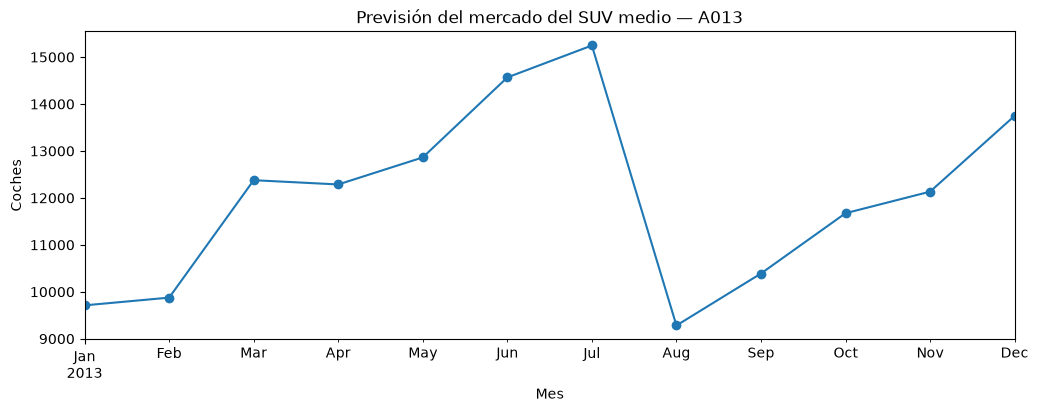

In [60]:
prevision_A013.plot(
    figsize=(12, 4),
    marker="o",
    title="Previsión del mercado del SUV medio — A013",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

La gráfica muestra un patrón claro que es ventas altas en primavera y comienzos del verano, caída en agosto y recuperación hacia diciembre

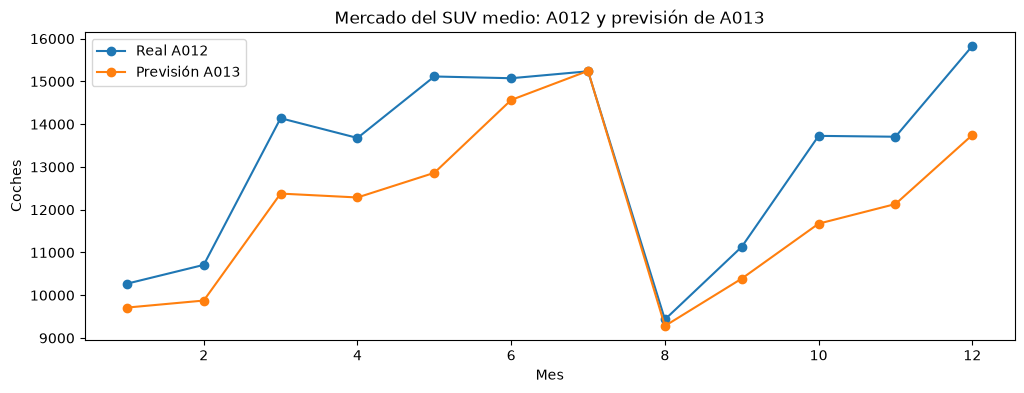

In [61]:
comparacion_anual = pd.DataFrame({
    "Real A012": y.loc["2012"].to_numpy(),
    "Previsión A013": prevision_A013.to_numpy()
}, index=range(1, 13))

comparacion_anual.plot(
    figsize=(12, 4),
    marker="o",
    title="Mercado del SUV medio: A012 y previsión de A013",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

## Crecimiento del año completo (AÑO 13)

In [62]:
totales = comparacion_anual.sum()

crecimiento = (
    totales["Previsión A013"] / totales["Real A012"] - 1
) * 100

print(totales.round(0))
print(f"Crecimiento previsto: {crecimiento:.1f}%")

Real A012         158056.0
Previsión A013    144153.0
dtype: float64
Crecimiento previsto: -8.8%


In [63]:
importlib.reload(modelo_demanda)

y, X = modelo_demanda.cargar_datos("MSUV")

X_A013["adelanto_compras"] = 0

X_A013["caida_tras_adelanto"] = (
    X_A013.index.month <= 3
).astype(int)

X_A013 = X_A013[X.columns]

X_A013

,paro,confianza_consumidor,dias_laborables,semana_santa,adelanto_compras,caida_tras_adelanto
2013-01-01,13.78,77.7,21,0,0,1
2013-02-01,13.78,77.7,20,0,0,1
2013-03-01,13.78,77.7,22,0,0,1
2013-04-01,13.78,77.7,21,1,0,0
2013-05-01,13.78,77.7,20,0,0,0
2013-06-01,13.78,77.7,22,0,0,0
2013-07-01,13.78,77.7,23,0,0,0
2013-08-01,13.78,77.7,21,0,0,0
2013-09-01,13.78,77.7,22,0,0,0
2013-10-01,13.78,77.7,21,0,0,0


In [64]:
print("Calculando la previsión con sucesos...", flush=True)

prevision_A013_sucesos = modelo_demanda.prever_modelo(
    y, X, X_A013
)

prevision_A013_sucesos.round(0)

Calculando la previsión con sucesos...


2013-01-01     9711.0
2013-02-01     9876.0
2013-03-01    12377.0
2013-04-01    12286.0
2013-05-01    12863.0
2013-06-01    14567.0
2013-07-01    15247.0
2013-08-01     9282.0
2013-09-01    10389.0
2013-10-01    11674.0
2013-11-01    12133.0
2013-12-01    13748.0
Freq: MS, Name: predicted_mean, dtype: float64

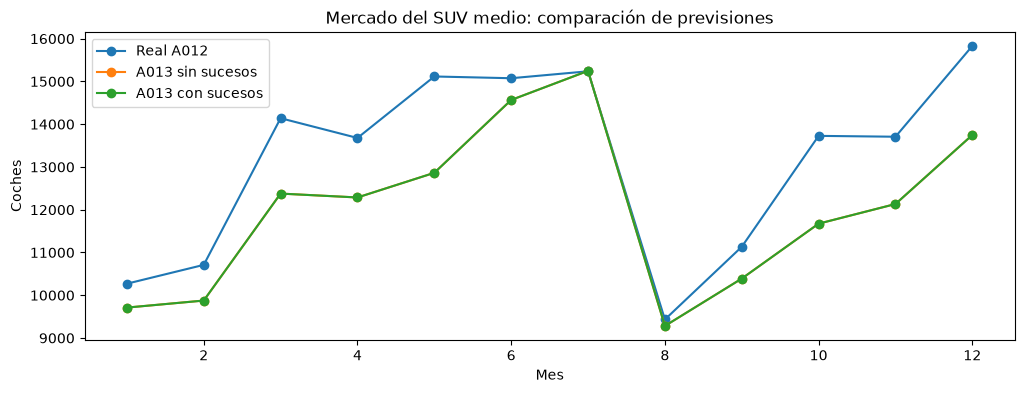

In [65]:
comparacion_sucesos = pd.DataFrame({
    "Real A012": y.loc["2012"].to_numpy(),
    "A013 sin sucesos": prevision_A013.to_numpy(),
    "A013 con sucesos": prevision_A013_sucesos.to_numpy()
}, index=range(1, 13))

comparacion_sucesos.plot(
    figsize=(12, 4),
    marker="o",
    title="Mercado del SUV medio: comparación de previsiones",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [66]:
total_A012 = y.loc["2012"].sum()
total_A013 = prevision_A013_sucesos.sum()

variacion = (total_A013 / total_A012 - 1) * 100

print(f"Real A012: {total_A012:.0f} coches")
print(f"Previsión A013 con sucesos: {total_A013:.0f} coches")
print(f"Variación prevista: {variacion:.1f}%")

Real A012: 158056 coches
Previsión A013 con sucesos: 144153 coches
Variación prevista: -8.8%


## ESCENARIO PESIMISTA

In [67]:
X_A013_pesimista = X_A013.copy()

X_A013_pesimista["paro"] = X_A013["paro"] + 2

X_A013_pesimista["caida_tras_adelanto"] = (
    X_A013_pesimista.index.month <= 6
).astype(int)

X_A013_pesimista

,paro,confianza_consumidor,dias_laborables,semana_santa,adelanto_compras,caida_tras_adelanto
2013-01-01,15.78,77.7,21,0,0,1
2013-02-01,15.78,77.7,20,0,0,1
2013-03-01,15.78,77.7,22,0,0,1
2013-04-01,15.78,77.7,21,1,0,1
2013-05-01,15.78,77.7,20,0,0,1
2013-06-01,15.78,77.7,22,0,0,1
2013-07-01,15.78,77.7,23,0,0,0
2013-08-01,15.78,77.7,21,0,0,0
2013-09-01,15.78,77.7,22,0,0,0
2013-10-01,15.78,77.7,21,0,0,0


CÁLCULO DE PREVISIÓN:

In [68]:
print("Calculando el escenario pesimista:", flush=True)

prevision_A013_pesimista = modelo_demanda.prever_modelo(
    y, X, X_A013_pesimista
)

prevision_A013_pesimista.round(0)

Calculando el escenario pesimista:


2013-01-01     9621.0
2013-02-01     9784.0
2013-03-01    12263.0
2013-04-01    10720.0
2013-05-01    11223.0
2013-06-01    12710.0
2013-07-01    15105.0
2013-08-01     9196.0
2013-09-01    10293.0
2013-10-01    11566.0
2013-11-01    12021.0
2013-12-01    13620.0
Freq: MS, Name: predicted_mean, dtype: float64

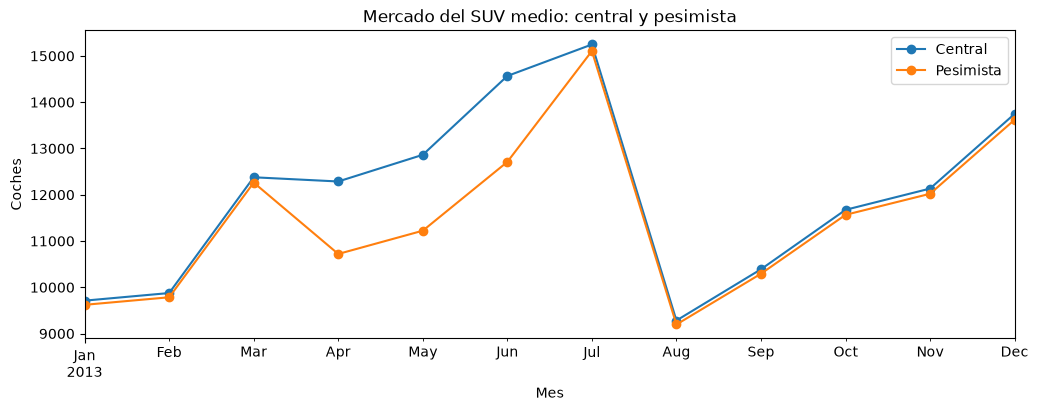

In [69]:

'''
Vamos a comparar los escenarios central y pesimista
'''
comparacion_escenarios = pd.DataFrame({
    "Central": prevision_A013_sucesos,
    "Pesimista": prevision_A013_pesimista
})

comparacion_escenarios.plot(
    figsize=(12, 4),
    marker="o",
    title="Mercado del SUV medio: central y pesimista",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [70]:
totales_escenarios = comparacion_escenarios.sum()

resumen_escenarios = pd.DataFrame({
    "Previsión A013 (coches)": totales_escenarios.round(0),
    "Variación vs A012 (%)": (
        (totales_escenarios / y.loc["2012"].sum() - 1) * 100
    ).round(1)
})

resumen_escenarios

,Previsión A013 (coches),Variación vs A012 (%)
Central,144153.0,-8.8
Pesimista,138122.0,-12.6


## ESCENARIO OPTIMISTA

In [71]:
X_A013_optimista = X_A013.copy()

X_A013_optimista["paro"] = X_A013["paro"] - 1
X_A013_optimista["caida_tras_adelanto"] = (
    X_A013_optimista.index.month == 1
).astype(int)

X_A013_optimista

,paro,confianza_consumidor,dias_laborables,semana_santa,adelanto_compras,caida_tras_adelanto
2013-01-01,12.78,77.7,21,0,0,1
2013-02-01,12.78,77.7,20,0,0,0
2013-03-01,12.78,77.7,22,0,0,0
2013-04-01,12.78,77.7,21,1,0,0
2013-05-01,12.78,77.7,20,0,0,0
2013-06-01,12.78,77.7,22,0,0,0
2013-07-01,12.78,77.7,23,0,0,0
2013-08-01,12.78,77.7,21,0,0,0
2013-09-01,12.78,77.7,22,0,0,0
2013-10-01,12.78,77.7,21,0,0,0


Cálculo las orevisiones en el escenario optimista

In [72]:
prevision_A013_optimista = modelo_demanda.prever_modelo(
    y, X, X_A013_optimista
)

prevision_A013_optimista.round(0)

2013-01-01     9757.0
2013-02-01    11266.0
2013-03-01    14120.0
2013-04-01    12344.0
2013-05-01    12923.0
2013-06-01    14635.0
2013-07-01    15318.0
2013-08-01     9325.0
2013-09-01    10438.0
2013-10-01    11728.0
2013-11-01    12190.0
2013-12-01    13812.0
Freq: MS, Name: predicted_mean, dtype: float64

In [73]:
'''
Comparación con el escenario central
'''

comparacion_escenarios["Optimista"] = prevision_A013_optimista

totales_escenarios = comparacion_escenarios.sum()

resumen_escenarios = pd.DataFrame({
    "Previsión A013 (coches)": totales_escenarios.round(0),
    "Variación vs A012 (%)": (
        (totales_escenarios / y.loc["2012"].sum() - 1) * 100
    ).round(1)
})

resumen_escenarios

,Previsión A013 (coches),Variación vs A012 (%)
Central,144153.0,-8.8
Pesimista,138122.0,-12.6
Optimista,147855.0,-6.5


## COMPARACIÓN DE LOS TRES ESCENARIOS

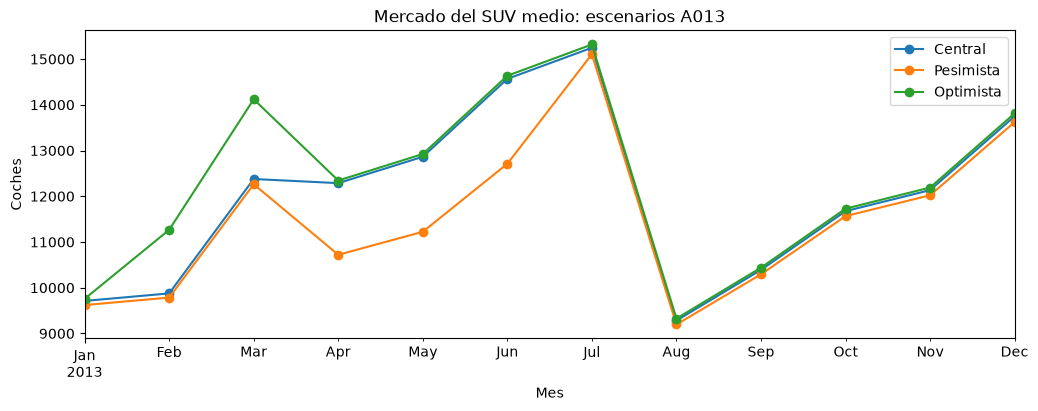

In [74]:
comparacion_escenarios.plot(
    figsize=(12, 4),
    marker="o",
    title="Mercado del SUV medio: escenarios A013",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

### Comparación de escenarios

Las diferencias dependen de cuánto dura la caída tras
el adelanto de compras
- Optimista: 1 mes
- Central: 3 meses
- Pesimista: 6 meses

La previsión anual es de 147.855 coches en el optimista, 144.153
en el central y 138.122 en el pesimista. Con los supuestos incluidos,
los tres quedan por debajo de las ventas de A012.

In [75]:
segmentos = pd.read_csv(
    RAIZ / "data" / "segmentos.csv",
    keep_default_na=False
)

segmentos

,segmento,descripcion,letra,primer_mes,unidades_totales,unidades_ult_anio,codigos,codigos_A013,codigos_nuevos_A013,pvp_medio,...,prima_co2_eur,vm_tarifa_eur,cvp_tarifa_eur,vm_real_eur,cvp_real_eur,vm_real_0_90_eur,vm_real_91_180_eur,vm_real_mas_180_eur,credito_dia_0_90_eur,credito_dia_91_180_eur
0,B,Pequeño,D,A0030101,11005,1764,16,5,2,17534.0,...,2555.0,2374.0,-533.0,1910.0,-69.0,1717.0,1745.0,1583.0,0.37,1.87
1,C,Compacto,B,A0030101,27809,4189,10,1,0,25884.0,...,1952.0,1609.0,2063.0,2485.0,1187.0,2305.0,2572.0,3064.0,0.57,2.83
2,MD,Berlina media,G,A0030101,13144,755,10,4,0,34968.0,...,2082.0,2706.0,4855.0,3802.0,3760.0,3517.0,3701.0,3964.0,0.75,3.77
3,SSUV,SUV pequeño,D,A0080401,22595,6230,10,2,1,24042.0,...,2830.0,1505.0,3328.0,2265.0,2568.0,1976.0,2024.0,1978.0,0.52,2.58
4,CSUV,SUV compacto,D,A0120801,1435,1435,1,3,2,32335.0,...,1912.0,2926.0,3248.0,2375.0,3798.0,2370.0,2470.0,,0.72,3.59
5,MSUV,SUV medio,K,A0050101,46230,8213,9,4,2,32809.0,...,4203.0,1761.0,6021.0,2068.0,5714.0,1895.0,2090.0,2422.0,0.71,3.53
6,S,Descapotable,N,A0030101,2812,589,7,2,0,31617.0,...,4493.0,2173.0,4669.0,2210.0,4631.0,1887.0,2143.0,2411.0,0.68,3.40


In [76]:
y_B, X_B = modelo_demanda.cargar_datos("B")

resultado_B = modelo_demanda.evaluar_modelo(y_B, X_B)

print("¿Ha convergido?", resultado_B["ha_convergido"])
resultado_B["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,22.9
Referencia estacional,13.9


In [77]:
'''
Donde falla el sarimax
'''

resultado_B["errores"].sort_values(
    "error_sarimax", ascending=False
).head(3)

,real,prevision,error_sarimax,error_referencia
2012-12-01,17227,26170.0,8943.0,2759
2012-11-01,15286,23321.0,8035.0,2751
2012-03-01,23891,30368.0,6477.0,4822


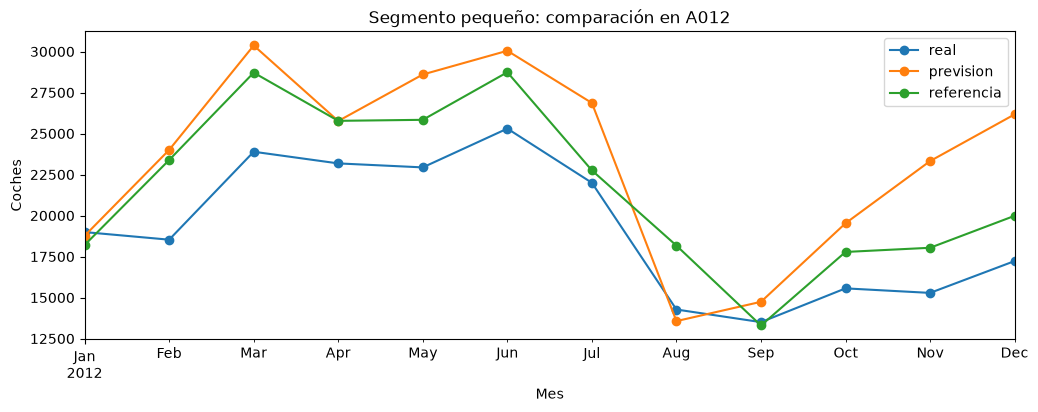

In [78]:
resultado_B["comparacion"].assign(
    referencia=resultado_B["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="Segmento pequeño: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [79]:
y_C, X_C = modelo_demanda.cargar_datos("C")

resultado_C = modelo_demanda.evaluar_modelo(y_C, X_C)

print("¿Ha convergido?", resultado_C["ha_convergido"])
resultado_C["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,51.0
Referencia estacional,19.3


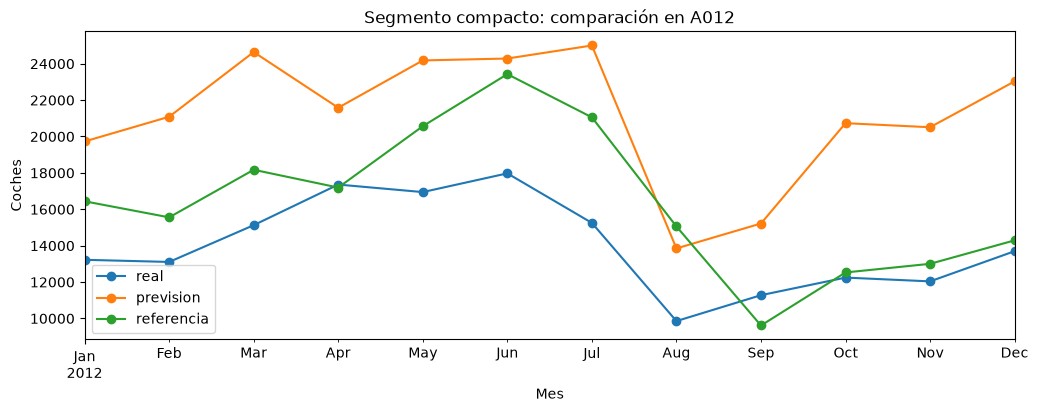

In [80]:
resultado_C["comparacion"].assign(
    referencia=resultado_C["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="Segmento compacto: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

Ahora con berlina

In [81]:
y_MD, X_MD = modelo_demanda.cargar_datos("MD")

resultado_MD = modelo_demanda.evaluar_modelo(y_MD, X_MD)

print("¿Ha convergido?", resultado_MD["ha_convergido"])
resultado_MD["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,72.5
Referencia estacional,49.2


COMPROBACIÓN

In [82]:
y_MD, X_MD = modelo_demanda.cargar_datos("MD")

resultado_MD = modelo_demanda.evaluar_modelo(y_MD, X_MD)

print("¿Ha convergido?", resultado_MD["ha_convergido"])
resultado_MD["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,72.5
Referencia estacional,49.2


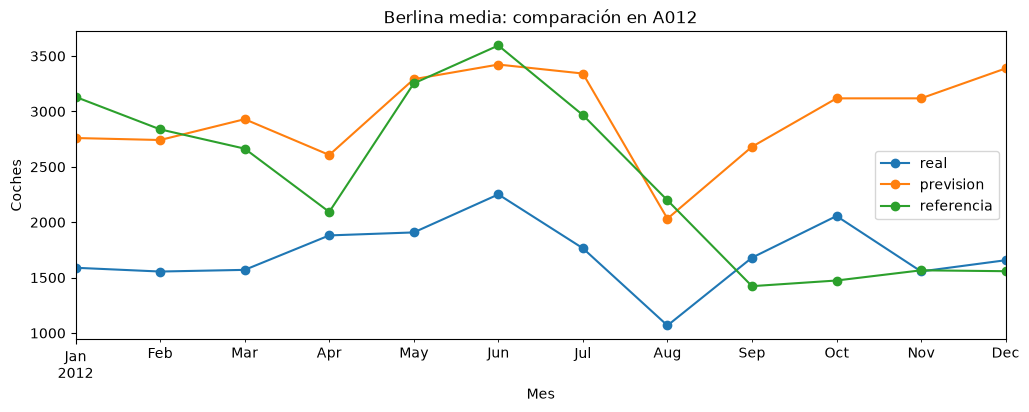

In [83]:
resultado_MD["comparacion"].assign(
    referencia=resultado_MD["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="Berlina media: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

Gráfica de los últimos meses

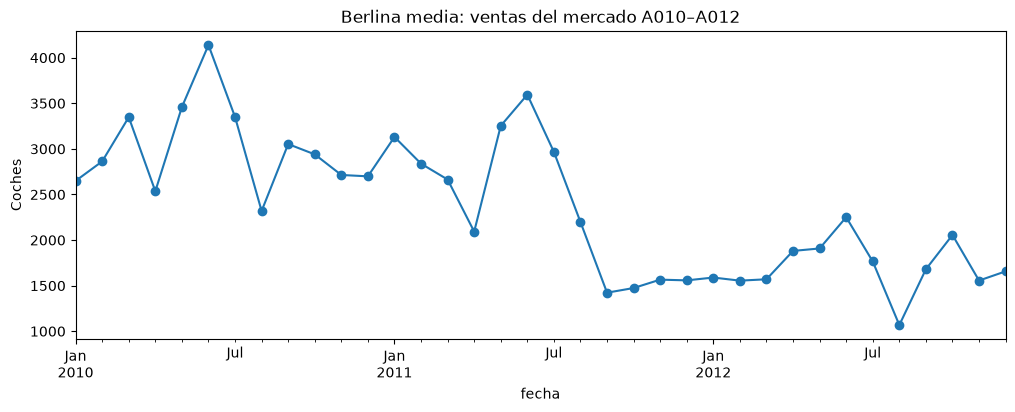

In [84]:
y_MD.loc["2010":"2012"].plot(
    figsize=(12, 4),
    marker="o",
    title="Berlina media: ventas del mercado A010–A012",
    ylabel="Coches"
)

plt.show()

In [85]:
importlib.reload(modelo_demanda)
import numpy as np

entrenamiento_MD = y_MD.index.year <= 2011

modelo_MD_ajustado = modelo_demanda.entrenar_modelo(
    y_MD[entrenamiento_MD],
    X_MD[entrenamiento_MD],
    orden=(1, 1, 0)
)

prevision_MD_ajustada = np.exp(
    modelo_MD_ajustado.forecast(
        steps=12,
        exog=X_MD[~entrenamiento_MD]
    )
)

real_MD = y_MD[~entrenamiento_MD]
wape_MD_ajustado = (
    (real_MD - prevision_MD_ajustada).abs().sum()
    / real_MD.sum() * 100
)

print("¿Ha convergido?", modelo_MD_ajustado.mle_retvals["converged"])
print(f"WAPE ajustado: {wape_MD_ajustado:.1f}%")

¿Ha convergido? True
WAPE ajustado: 43.6%


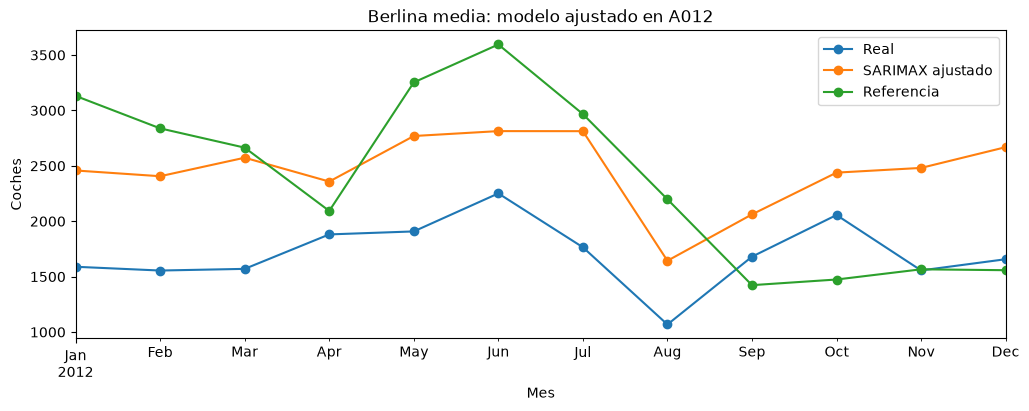

In [86]:
pd.DataFrame({
    "Real": real_MD,
    "SARIMAX ajustado": prevision_MD_ajustada,
    "Referencia": resultado_MD["referencia"]
}).plot(
    figsize=(12, 4),
    marker="o",
    title="Berlina media: modelo ajustado en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [87]:
prevision_MD_ultimo = pd.Series(
    y_MD[entrenamiento_MD].iloc[-1],
    index=real_MD.index
)

wape_MD_ultimo = (
    (real_MD - prevision_MD_ultimo).abs().sum()
    / real_MD.sum() * 100
)

print(f"WAPE último valor: {wape_MD_ultimo:.1f}%")

WAPE último valor: 13.8%


In [88]:
y_SSUV, X_SSUV = modelo_demanda.cargar_datos("SSUV")

resultado_SSUV = modelo_demanda.evaluar_modelo(y_SSUV, X_SSUV)

print("¿Ha convergido?", resultado_SSUV["ha_convergido"])
resultado_SSUV["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,12.2
Referencia estacional,14.3


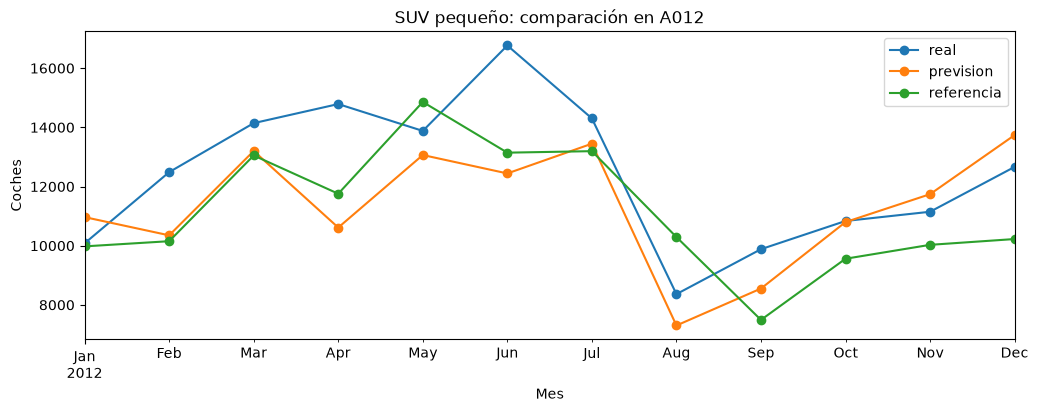

In [89]:
resultado_SSUV["comparacion"].assign(
    referencia=resultado_SSUV["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="SUV pequeño: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [90]:
y_CSUV, X_CSUV = modelo_demanda.cargar_datos("CSUV")

resultado_CSUV = modelo_demanda.evaluar_modelo(y_CSUV, X_CSUV)

print("¿Ha convergido?", resultado_CSUV["ha_convergido"])
resultado_CSUV["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,23.1
Referencia estacional,13.3


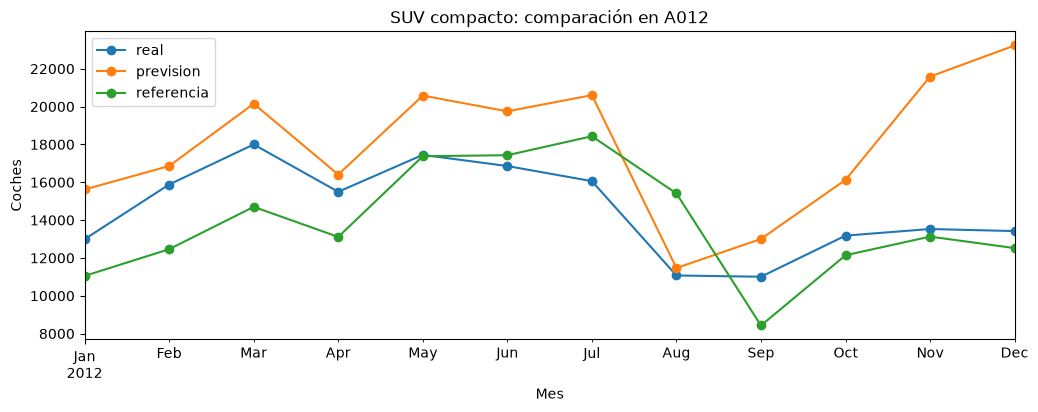

In [91]:
resultado_CSUV["comparacion"].assign(
    referencia=resultado_CSUV["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="SUV compacto: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [92]:
y_S, X_S = modelo_demanda.cargar_datos("S")

resultado_S = modelo_demanda.evaluar_modelo(y_S, X_S)

print("¿Ha convergido?", resultado_S["ha_convergido"])
resultado_S["metricas"].round(1)

¿Ha convergido? True


,WAPE (%)
SARIMAX,31.1
Referencia estacional,32.1


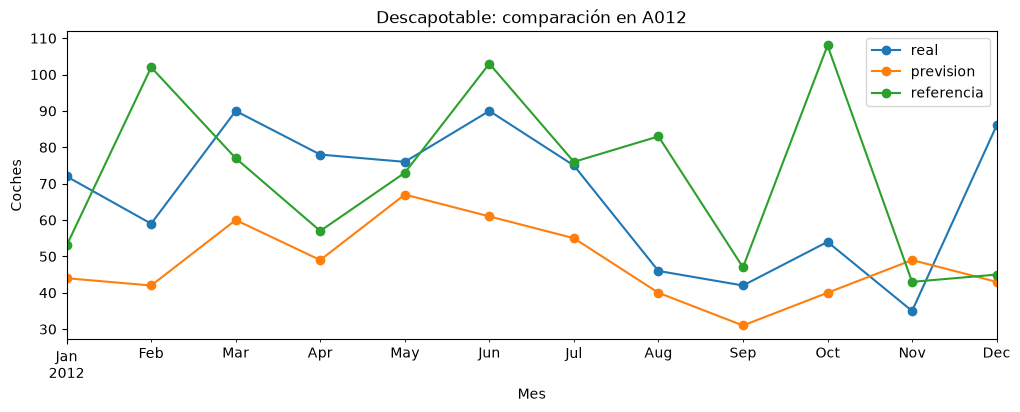

In [93]:
resultado_S["comparacion"].assign(
    referencia=resultado_S["referencia"]
).plot(
    figsize=(12, 4),
    marker="o",
    title="Descapotable: comparación en A012",
    xlabel="Mes",
    ylabel="Coches"
)

plt.show()

In [94]:
real_S = y_S.loc["2012"]

prevision_S_media = pd.Series(
    y_S.loc["2011"].mean(),
    index=real_S.index
)

wape_S_media = (
    (real_S - prevision_S_media).abs().sum()
    / real_S.sum() * 100
)

print(f"WAPE media de A011: {wape_S_media:.1f}%")

WAPE media de A011: 23.3%


In [95]:
seleccion_modelos = pd.DataFrame({
    "Segmento": ["B", "C", "MD", "SSUV", "CSUV", "MSUV", "S"],
    "Método provisional": [
        "Referencia estacional",
        "Referencia estacional",
        "Último valor",
        "SARIMAX",
        "Referencia estacional",
        "SARIMAX",
        "Media del año anterior"
    ],
    "WAPE A012 (%)": [13.9, 19.3, 13.8, 12.2, 13.3, 9.0, 23.3]
})

seleccion_modelos

,Segmento,Método provisional,WAPE A012 (%)
0,B,Referencia estacional,13.9
1,C,Referencia estacional,19.3
2,MD,Último valor,13.8
3,SSUV,SARIMAX,12.2
4,CSUV,Referencia estacional,13.3
5,MSUV,SARIMAX,9.0
6,S,Media del año anterior,23.3


In [96]:
prevision_B_A013 = pd.Series(
    y_B.loc["2012"].to_numpy(),
    index=X_A013.index,
    name="Previsión B A013"
)

prevision_B_A013

2013-01-01    18993
2013-02-01    18530
2013-03-01    23891
2013-04-01    23180
2013-05-01    22937
2013-06-01    25302
2013-07-01    21999
2013-08-01    14273
2013-09-01    13504
2013-10-01    15562
2013-11-01    15286
2013-12-01    17227
Freq: MS, Name: Previsión B A013, dtype: int64

## Modelo final: mercado total × peso del segmento

### ¿Cuánto vamos a vender en A013?

In [97]:
importlib.reload(sys.modules.get("modelo_mercado") or __import__("modelo_mercado"))
import modelo_mercado as mm

P, macro = mm.cargar_datos()
escenarios = mm.cargar_escenarios()
X_central = mm.variables_A013(macro, escenarios["central"])

In [98]:
validacion = mm.validar(P, X_central)
validacion.pivot(index="segmento", columns="anio", values="WAPE (%)").round(1)

c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


anio,2010,2011,2012
segmento,,,
B,9.5,8.4,12.5
C,7.7,11.9,12.1
CSUV,9.0,9.3,13.9
MD,12.1,21.8,15.7
MSUV,16.1,13.6,8.3
S,62.7,223.0,24.8
SSUV,21.1,30.3,14.7
TOTAL,6.5,10.6,10.5


### ¿Qué pasa si el año sale mejor o peor?

In [99]:
prevision = {}
for nombre, esc in escenarios.items():
    prev, _, _ = mm.prever_mercado(P, mm.variables_A013(macro, esc), 2013)
    prevision[nombre] = prev

resumen = pd.DataFrame({k: v.sum() for k, v in prevision.items()}).round(0)
resumen["A012"] = P.loc["2012"].sum()
resumen

c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,pesimista,central,optimista,A012
B,148402.0,175895.0,211679.0,230684
C,105095.0,124547.0,149814.0,168093
MD,10265.0,12163.0,14631.0,20536
SSUV,134946.0,159882.0,192321.0,149332
CSUV,133550.0,158209.0,190340.0,174933
MSUV,121060.0,143392.0,172435.0,158056
S,478.0,566.0,681.0,803


### Cuota base de Kaido para A013

La cuota se calcula con la **demanda real** (ventas menos automatriculaciones) dividida entre el mercado del segmento. Como referencia se toman los meses de enero a octubre de A012, para dejar fuera el adelanto de compras de noviembre y diciembre. En los coches recién lanzados (C y CSUV) solo se usan los últimos meses, porque su cuota todavía estaba subiendo.

In [100]:
mercado = pd.read_csv(RAIZ / "data" / "mercado_mensual.csv",
                      keep_default_na=False, na_values=[""])

cuota_anual = mercado.groupby(["anio", "segmento"])[["marca_propia", "unidades"]].sum()
cuota_anual = (cuota_anual["marca_propia"] / cuota_anual["unidades"] * 100).unstack().round(2)
cuota_anual.loc["A008":]

segmento,B,C,CSUV,MD,MSUV,S,SSUV
anio,,,,,,,
A008,0.53,1.69,0.00,5.04,8.05,77.19,2.84
A009,0.62,1.75,0.00,4.66,6.81,56.25,5.96
A010,0.49,1.94,0.00,4.06,5.66,62.61,5.13
A011,0.69,1.79,0.00,4.06,5.99,61.13,4.13
A012,0.76,2.49,0.82,3.68,5.20,73.35,4.17


### ¿Cuál es la demanda real de Kaido?

In [101]:
ventas = pd.read_csv(RAIZ / "data" / "ventas_mensual.csv",
                     keep_default_na=False, na_values=[""])

# Demanda de Kaido = ventas - automatriculaciones
kaido = ventas.groupby(["anio", "mes", "segmento"])[["unidades", "u_automatriculacion"]].sum()
kaido["demanda"] = kaido["unidades"] - kaido["u_automatriculacion"]

merc = mercado.groupby(["anio", "mes", "segmento"])["unidades"].sum()
cuota_mensual = (kaido["demanda"] / merc * 100).unstack()

# Referencia: A012 de enero a octubre (sin el adelanto de nov-dic)
ref = cuota_mensual.loc["A012"].loc[1:10]
cuota_base = ref.mean()

# Coches recién lanzados: solo los últimos meses
cuota_base["C"] = ref.loc[8:10, "C"].mean()        # BD, lanzado en enero de A012
cuota_base["CSUV"] = ref.loc[9:10, "CSUV"].mean()  # DF, lanzado en agosto de A012

cuota_base.round(2)

segmento
B        0.69
C        2.54
CSUV     1.83
MD       3.07
MSUV     4.55
S       62.76
SSUV     3.86
dtype: float64

###  Demanda de Kaido en A013 por escenario (mercado × cuota)

In [ ]:
import json

with open(RAIZ / "config" / "supuestos.json", encoding="utf-8") as f:
    supuestos = json.load(f)

SEGMENTOS_CON_LANZAMIENTO = ["B", "SSUV", "CSUV", "MSUV"]   
EFECTO_LANZAMIENTO = 0.10   # +10 % de cuota: media histórica tras una renovación de gama

def cuota_A013(escenario):
    """Cuota mensual de Kaido en A013 (en tanto por uno) para un escenario."""
    meses = pd.date_range("2013-01-01", periods=12, freq="MS")
    cuota = pd.DataFrame({s: cuota_base[s] / 100 for s in cuota_base.index}, index=meses)

    # Mes de lanzamiento: abril, o más tarde si el escenario trae retraso
    mes_lanz = supuestos["mes_lanzamiento_A013"] + escenario["retraso_lanzamiento"]
    tras_lanz = meses.month >= mes_lanz
    for s in SEGMENTOS_CON_LANZAMIENTO:
        cuota.loc[tras_lanz, s] *= (1 + EFECTO_LANZAMIENTO) * escenario["producto_factor"]
    return cuota

# Demanda de Kaido = mercado previsto x cuota
demanda = {}
for nombre, esc in escenarios.items():
    demanda[nombre] = (prevision[nombre] * cuota_A013(esc)).round(0)

resumen_kaido = pd.DataFrame({k: v.sum() for k, v in demanda.items()})
resumen_kaido.loc["TOTAL"] = resumen_kaido.sum()
resumen_kaido

,pesimista,central,optimista
B,1019.0,1300.0,1681.0
C,2673.0,3168.0,3809.0
CSUV,2437.0,3115.0,4028.0
MD,316.0,374.0,451.0
MSUV,5481.0,7015.0,9087.0
S,300.0,355.0,429.0
SSUV,5188.0,6637.0,8588.0
TOTAL,17414.0,21964.0,28073.0


### ¿Cuántos coches fabricamos y cuánto stock queremos?

In [ ]:
stock = pd.read_csv(RAIZ / "data" / "stock_mensual.csv",
                    keep_default_na=False, na_values=[""])
wholesale_A012 = stock[stock["anio"] == "A012"].pivot(
    index="mes", columns="segmento", values="wholesale")

#Stock en la red a fin de diciembre de A012
stock_inicial = (stock[(stock["anio"] == "A012") & (stock["mes"] == 12)]
                 .set_index("segmento")["stock_total"])


en_camino = wholesale_A012.loc[8:12].mean().round(0)


errores = {s: [] for s in mm.SEGMENTOS}
for anio in (2010, 2011, 2012):
    prev, _, _ = mm.prever_mercado(P, X_central, anio)
    for s in mm.SEGMENTOS:
        errores[s] += list(np.log(P[s].loc[str(anio)].to_numpy() / prev[s].to_numpy()))
error_mercado = pd.Series({s: np.std(e) for s, e in errores.items()})


error_cuota = np.log(cuota_mensual.loc["A012"].loc[1:10].replace(0, np.nan)).std()

error_cuota[["C", "CSUV"]] = error_cuota.drop(["C", "CSUV"]).median()

sigma_rel = np.sqrt(error_mercado**2 + error_cuota**2)

inicio = pd.DataFrame({
    "stock_dic_A012": stock_inicial,
    "en_camino_mes": en_camino,
    "sigma_rel": sigma_rel.round(3),
})
inicio

c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\kaido-motors\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,stock_dic_A012,en_camino_mes,sigma_rel
B,97,122.0,0.368
C,1107,453.0,0.316
CSUV,1011,489.0,0.327
MD,125,26.0,0.411
MSUV,536,578.0,0.202
S,1,34.0,0.702
SSUV,0,357.0,0.312


In [ ]:
import simulacion as sim
importlib.reload(sim)

z_elegida, costes_z = sim.elegir_z(demanda, escenarios, inicio)
print((costes_z / 1000).round(0))   # coste de equivocarse en miles de EUR, 
z_elegida

z       0.00    0.84    1.28    1.65    2.05
B       86.0   105.0   120.0   135.0   151.0
C      697.0   598.0   577.0   574.0   579.0
CSUV  1161.0   825.0   734.0   690.0   665.0
MD     180.0   109.0    90.0    80.0    73.0
MSUV  2687.0  1469.0  1117.0   935.0   822.0
S      384.0   210.0   168.0   149.0   137.0
SSUV  2332.0  1515.0  1302.0  1205.0  1160.0


B       0.00
C       1.65
CSUV    2.05
MD      2.05
MSUV    2.05
S       2.05
SSUV    2.05
dtype: float64

In [105]:
tabla5, rangos, plan = sim.simular_escenarios(demanda, escenarios, inicio, z_elegida)

pd.set_option("display.float_format", "{:,.0f}".format)
tabla5.loc["TOTAL"]     # la tabla 5 del enunciado; cambia "TOTAL" por "MSUV", "C", etc.

escenario,pesimista,central,optimista
Coches vendidos,"16,824","21,404","27,104"
Coches fabricados (llegadas A013),"15,137","20,001","25,629"
Stock medio en la red (coches),"2,756","2,508","2,173"
Stock medio (meses de venta),2,1,1
Coches >90 días a fin de año,175,103,65
Coste del stock (EUR),"2,356,327","2,410,652","2,348,131"
Ventas perdidas (coches),436,414,806
Ventas perdidas (EUR de CVP),"1,450,391","837,549","1,829,584"
Transfers (coches),280,307,603
Transfers (EUR),"301,818","267,605","557,421"


### Cuánto cuesta equivocarse y qué recomendamos?

In [106]:
eco = sim.cargar_economia()
asimetria = pd.DataFrame({
    "Pasarse: 1 coche parado 1 mes (EUR)": 60,
    "Pasarse: VM extra si pasa de 90 días (EUR)": eco["vm_91_180"] - eco["vm_0_90"],
    "Quedarse corto: venta perdida (CVP, EUR)": eco["cvp_real"],
    "Quedarse corto: transfer (20 % benef. bruto, EUR)": 0.2 * eco["beneficio_bruto"],
    "CVP si se carga la prima CO2 (EUR)": eco["cvp_real"] - eco["prima_co2"],
})
asimetria["Veces que cuesta más quedarse corto"] = (eco["cvp_real"] / 60).round(0)
asimetria.round(0)

,Pasarse: 1 coche parado 1 mes (EUR),Pasarse: VM extra si pasa de 90 días (EUR),"Quedarse corto: venta perdida (CVP, EUR)","Quedarse corto: transfer (20 % benef. bruto, EUR)",CVP si se carga la prima CO2 (EUR),Veces que cuesta más quedarse corto
segmento,,,,,,
B,60,28,-69,368,"-2,624",-1
C,60,267,"1,187",734,-765,20
MD,60,184,"3,760","1,512","1,678",63
SSUV,60,48,"2,568",967,-262,43
CSUV,60,100,"3,798","1,235","1,886",63
MSUV,60,195,"5,714","1,556","1,511",95
S,60,256,"4,631","1,368",138,77


### Descomposición del margen en el escenario pesimista

Partiendo del central, se añaden uno a uno los sucesos del pesimista para ver cuánto margen quita cada uno: primero solo la menor demanda, luego el arancel y por último la prima de CO₂.

In [ ]:
import copy

pasos = {}
esc = copy.deepcopy(escenarios)

# Pesimista sin prima ni arancel: solo el efecto de la demanda
esc["pesimista"].update(prima_co2=False, arancel_pct_coste=0.0)
t, _, _ = sim.simular_escenarios(demanda, esc, inicio, z_elegida)
pasos["Central"] = t.loc["TOTAL", "central"]["Margen de la marca CVP (EUR)"]
pasos["Pesimista: solo menos demanda"] = t.loc["TOTAL", "pesimista"]["Margen de la marca CVP (EUR)"]

#  + arancel
esc["pesimista"]["arancel_pct_coste"] = escenarios["pesimista"]["arancel_pct_coste"]
t, _, _ = sim.simular_escenarios(demanda, esc, inicio, z_elegida)
pasos["+ arancel"] = t.loc["TOTAL", "pesimista"]["Margen de la marca CVP (EUR)"]

# + prima de CO2 (pesimista completo)
t, _, _ = sim.simular_escenarios(demanda, escenarios, inicio, z_elegida)
pasos["+ prima CO2 (pesimista completo)"] = t.loc["TOTAL", "pesimista"]["Margen de la marca CVP (EUR)"]

descomposicion = pd.Series(pasos, name="Margen CVP (M EUR)") / 1e6
descomposicion.round(1)

Central                            77
Pesimista: solo menos demanda      59
+ arancel                          48
+ prima CO2 (pesimista completo)   -3
Name: Margen CVP (M EUR), dtype: float64